# Noria · 01 — EDA de `application_train.csv`

Exploration initiale de la table principale du dataset Kaggle *Home Credit Default Risk*.

**Périmètre de ce notebook** : observer et documenter uniquement.
- Aucune modification de `data/raw/`.
- Aucun nettoyage, aucune transformation, aucun split (le split 70/15/15 stratifié à graine fixe viendra à la session suivante).
- Sorties : `reports/missing_values.csv` et les figures dans `reports/figures/`.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw" / "application_train.csv"
REPORTS = ROOT / "reports"
FIGURES = REPORTS / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_rows", 130)
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
sns.set_theme(style="whitegrid")

def save(fig, name):
    fig.savefig(FIGURES / name, dpi=120, bbox_inches="tight")
    print(f"Figure sauvegardée : reports/figures/{name}")

## 1. Chargement et vue d'ensemble

In [2]:
df = pd.read_csv(RAW)

n_rows, n_cols = df.shape
num_cols = df.select_dtypes(include="number").columns
cat_cols = df.select_dtypes(exclude="number").columns

print(f"Shape : {n_rows:,} lignes x {n_cols} colonnes")
print(f"Colonnes numériques   : {len(num_cols)}")
print(f"Colonnes catégorielles : {len(cat_cols)}")
print(f"Mémoire utilisée : {df.memory_usage(deep=True).sum() / 1024**2:,.1f} Mo")
print(f"SK_ID_CURR unique : {df['SK_ID_CURR'].is_unique}")
print()
print(df.dtypes.value_counts().rename("nb_colonnes").to_string())

Shape : 307,511 lignes x 122 colonnes
Colonnes numériques   : 106
Colonnes catégorielles : 16
Mémoire utilisée : 325.2 Mo
SK_ID_CURR unique : True

float64    65
int64      41
str        16


In [3]:
df.head()

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_TYPE_SUITE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,OWN_CAR_AGE,FLAG_MOBIL,FLAG_EMP_PHONE,FLAG_WORK_PHONE,...,FLAG_DOCUMENT_3,FLAG_DOCUMENT_4,FLAG_DOCUMENT_5,FLAG_DOCUMENT_6,FLAG_DOCUMENT_7,FLAG_DOCUMENT_8,FLAG_DOCUMENT_9,FLAG_DOCUMENT_10,FLAG_DOCUMENT_11,FLAG_DOCUMENT_12,FLAG_DOCUMENT_13,FLAG_DOCUMENT_14,FLAG_DOCUMENT_15,FLAG_DOCUMENT_16,FLAG_DOCUMENT_17,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,"202,500.0000","406,597.5000","24,700.5000","351,000.0000",Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.0188,-9461,-637,"-3,648.0000",-2120,NaN,1,1,0,...,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000
1,100003,0,Cash loans,F,N,N,0,"270,000.0000","1,293,502.5000","35,698.5000","1,129,500.0000",Family,State servant,Higher education,Married,House / apartment,0.0035,-16765,-1188,"-1,186.0000",-291,NaN,1,1,0,...,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
2,100004,0,Revolving loans,M,Y,Y,0,"67,500.0000","135,000.0000","6,750.0000","135,000.0000",Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.0100,-19046,-225,"-4,260.0000",-2531,26.0000,1,1,1,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
3,100006,0,Cash loans,F,N,Y,0,"135,000.0000","312,682.5000","29,686.5000","297,000.0000",Unaccompanied,Working,Secondary / secondary special,Civil marriage,House / apartment,0.0080,-19005,-3039,"-9,833.0000",-2437,NaN,1,1,0,...,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,"121,500.0000","513,000.0000","21,865.5000","513,000.0000",Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.0287,-19932,-3038,"-4,311.0000",-3458,NaN,1,1,0,...,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000


## 2. Variable cible `TARGET`

In [4]:
target_counts = df["TARGET"].value_counts().sort_index()
target_pct = df["TARGET"].value_counts(normalize=True).sort_index() * 100
target_summary = pd.DataFrame({"effectif": target_counts, "pourcentage": target_pct.round(2)})
target_summary.index = target_summary.index.map({0: "0 · remboursement normal", 1: "1 · difficultés (défaut)"})
display(target_summary)

ratio = target_counts[0] / target_counts[1]
print(f"Ratio de déséquilibre : {ratio:.2f} non-défauts pour 1 défaut  (1:{ratio:.1f})")
print(f"Taux de défaut global : {target_pct[1]:.2f} %")

,effectif,pourcentage
TARGET,,
0 · remboursement normal,282686,91.9300
1 · difficultés (défaut),24825,8.0700


Ratio de déséquilibre : 11.39 non-défauts pour 1 défaut  (1:11.4)
Taux de défaut global : 8.07 %


Figure sauvegardée : reports/figures/01_target_distribution.png


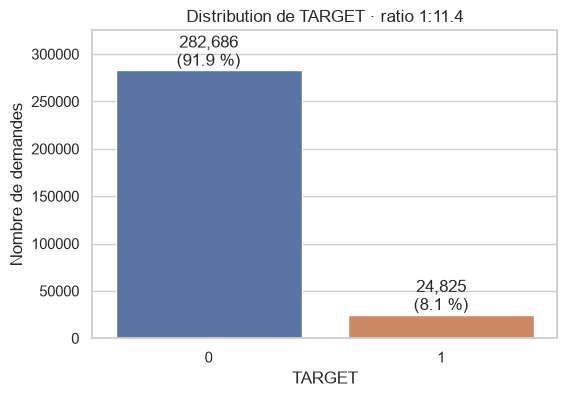

In [5]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.barplot(x=target_counts.index.astype(str), y=target_counts.values, hue=target_counts.index.astype(str),
            palette=["#4C72B0", "#DD8452"], legend=False, ax=ax)
for i, (n, p) in enumerate(zip(target_counts.values, target_pct.values)):
    ax.text(i, n, f"{n:,}\n({p:.1f} %)", ha="center", va="bottom")
ax.set_xlabel("TARGET")
ax.set_ylabel("Nombre de demandes")
ax.set_title(f"Distribution de TARGET · ratio 1:{ratio:.1f}")
ax.set_ylim(0, target_counts.max() * 1.15)
save(fig, "01_target_distribution.png")
plt.show()

## 3. Valeurs manquantes

In [6]:
missing = (
    pd.DataFrame({
        "colonne": df.columns,
        "nb_manquants": df.isna().sum().values,
        "pct_manquants": (df.isna().mean() * 100).round(2).values,
    })
    .query("nb_manquants > 0")
    .sort_values("pct_manquants", ascending=False)
    .reset_index(drop=True)
)
missing.to_csv(REPORTS / "missing_values.csv", index=False)
print("Sauvegardé : reports/missing_values.csv")

print(f"Colonnes avec au moins un manquant : {len(missing)} / {n_cols}")
for seuil in (20, 40, 50, 60):
    print(f"  > {seuil} % de manquants : {(missing['pct_manquants'] > seuil).sum()} colonnes")
print(f"Cellules manquantes au total : {df.isna().sum().sum() / df.size * 100:.2f} %")
missing

Sauvegardé : reports/missing_values.csv
Colonnes avec au moins un manquant : 67 / 122
  > 20 % de manquants : 50 colonnes
  > 40 % de manquants : 49 colonnes
  > 50 % de manquants : 41 colonnes
  > 60 % de manquants : 17 colonnes
Cellules manquantes au total : 24.40 %


,colonne,nb_manquants,pct_manquants
0,COMMONAREA_MEDI,214865,69.8700
1,COMMONAREA_AVG,214865,69.8700
2,COMMONAREA_MODE,214865,69.8700
3,NONLIVINGAPARTMENTS_MEDI,213514,69.4300
4,NONLIVINGAPARTMENTS_MODE,213514,69.4300
5,NONLIVINGAPARTMENTS_AVG,213514,69.4300
6,FONDKAPREMONT_MODE,210295,68.3900
7,LIVINGAPARTMENTS_MODE,210199,68.3500
8,LIVINGAPARTMENTS_MEDI,210199,68.3500
9,LIVINGAPARTMENTS_AVG,210199,68.3500


Figure sauvegardée : reports/figures/02_missing_values_top40.png


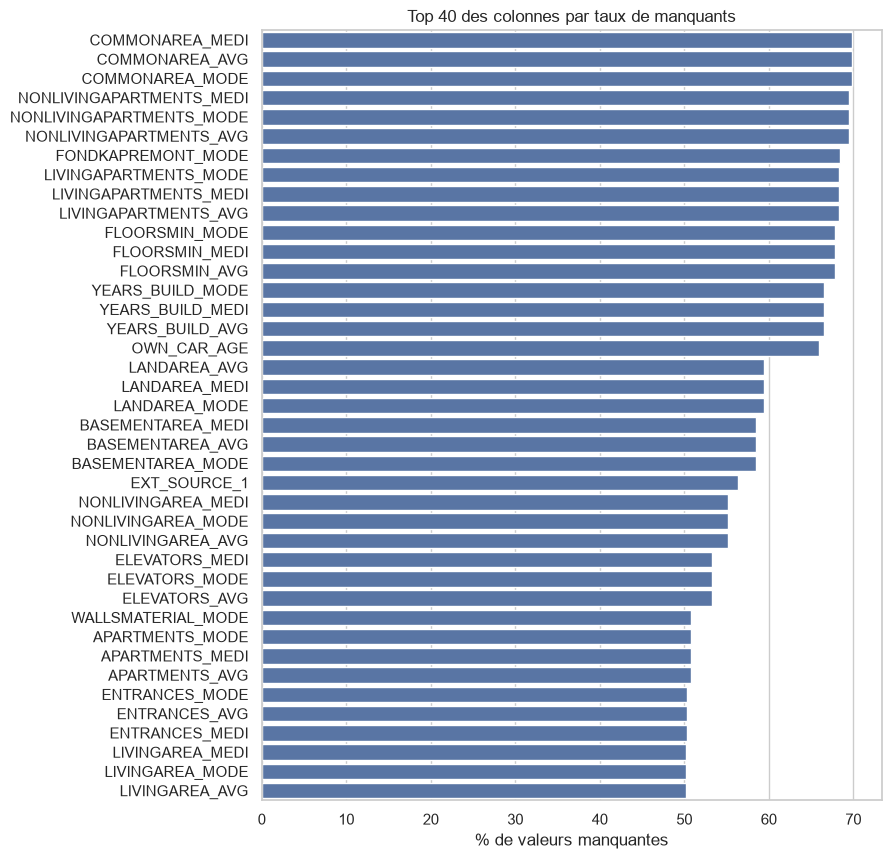

In [7]:
top = missing.head(40)
fig, ax = plt.subplots(figsize=(8, 10))
sns.barplot(data=top, y="colonne", x="pct_manquants", color="#4C72B0", ax=ax)
ax.set_xlabel("% de valeurs manquantes")
ax.set_ylabel("")
ax.set_title("Top 40 des colonnes par taux de manquants")
save(fig, "02_missing_values_top40.png")
plt.show()

Beaucoup de colonnes très manquantes sont les descripteurs du logement (`*_AVG`, `*_MODE`, `*_MEDI`).
On vérifie si elles manquent ensemble (même bloc de lignes) :

In [8]:
housing_cols = [c for c in df.columns if c.endswith(("_AVG", "_MODE", "_MEDI"))]
print(f"Colonnes logement (_AVG/_MODE/_MEDI) : {len(housing_cols)}")
all_missing = df[housing_cols].isna().all(axis=1)
print(f"Lignes où TOUTES ces colonnes manquent : {all_missing.sum():,} ({all_missing.mean() * 100:.2f} %)")

Colonnes logement (_AVG/_MODE/_MEDI) : 47
Lignes où TOUTES ces colonnes manquent : 145,755 (47.40 %)


## 4. Colonnes catégorielles

In [9]:
SUSPECTS = {"XNA", "XAP", "Unknown", "unknown", "nan", ""}

rows = []
for c in cat_cols:
    vc = df[c].value_counts(dropna=True)
    suspects = {v: int(n) for v, n in vc.items() if str(v).strip() in SUSPECTS}
    rows.append({
        "colonne": c,
        "nb_modalites": df[c].nunique(dropna=True),
        "nb_manquants": int(df[c].isna().sum()),
        "pct_manquants": round(df[c].isna().mean() * 100, 2),
        "valeurs_suspectes": suspects if suspects else "",
        "modalite_la_plus_rare": f"{vc.index[-1]} ({vc.iloc[-1]})",
    })
cat_summary = pd.DataFrame(rows).sort_values("nb_modalites", ascending=False).reset_index(drop=True)
cat_summary

,colonne,nb_modalites,nb_manquants,pct_manquants,valeurs_suspectes,modalite_la_plus_rare
0,ORGANIZATION_TYPE,58,0,0.0000,{'XNA': 55374},Industry: type 8 (24)
1,OCCUPATION_TYPE,18,96391,31.3500,,IT staff (526)
2,NAME_INCOME_TYPE,8,0,0.0000,,Maternity leave (5)
3,NAME_TYPE_SUITE,7,1292,0.4200,,Group of people (271)
4,WEEKDAY_APPR_PROCESS_START,7,0,0.0000,,SUNDAY (16181)
5,WALLSMATERIAL_MODE,7,156341,50.8400,,Others (1625)
6,NAME_FAMILY_STATUS,6,0,0.0000,{'Unknown': 2},Unknown (2)
7,NAME_HOUSING_TYPE,6,0,0.0000,,Co-op apartment (1122)
8,NAME_EDUCATION_TYPE,5,0,0.0000,,Academic degree (164)
9,FONDKAPREMONT_MODE,4,210295,68.3900,,org spec account (5619)


In [10]:
for c in ["CODE_GENDER", "NAME_FAMILY_STATUS", "NAME_INCOME_TYPE", "NAME_CONTRACT_TYPE"]:
    print(f"--- {c}")
    print(df[c].value_counts(dropna=False).to_string(), "\n")

--- CODE_GENDER
CODE_GENDER
F      202448
M      105059
XNA         4 

--- NAME_FAMILY_STATUS
NAME_FAMILY_STATUS
Married                 196432
Single / not married     45444
Civil marriage           29775
Separated                19770
Widow                    16088
Unknown                      2 

--- NAME_INCOME_TYPE
NAME_INCOME_TYPE
Working                 158774
Commercial associate     71617
Pensioner                55362
State servant            21703
Unemployed                  22
Student                     18
Businessman                 10
Maternity leave              5 

--- NAME_CONTRACT_TYPE
NAME_CONTRACT_TYPE
Cash loans         278232
Revolving loans     29279 



Observations à documenter (sans correction) :
- `CODE_GENDER = "XNA"` et `NAME_FAMILY_STATUS = "Unknown"` : quelques lignes seulement.
- `ORGANIZATION_TYPE = "XNA"` : volume important, croisé avec l'anomalie `DAYS_EMPLOYED` en section 5.
- Certaines colonnes ont des **flags numériques** (0/1) : elles sont comptées comme numériques mais sont de fait catégorielles.

In [11]:
binary_num = [c for c in num_cols if c != "TARGET" and df[c].dropna().isin([0, 1]).all()]
flag_doc = [c for c in binary_num if c.startswith("FLAG_DOCUMENT_")]
print(f"Colonnes numériques binaires (0/1) hors TARGET : {len(binary_num)} (dont {len(flag_doc)} FLAG_DOCUMENT_*)")

Colonnes numériques binaires (0/1) hors TARGET : 32 (dont 20 FLAG_DOCUMENT_*)


## 5. Colonnes `DAYS_*` et `AMT_*`

In [12]:
days_cols = [c for c in df.columns if c.startswith("DAYS_")]
amt_cols = [c for c in df.columns if c.startswith("AMT_")]
print("DAYS_* :", days_cols)
display(df[days_cols].describe().T)

DAYS_* : ['DAYS_BIRTH', 'DAYS_EMPLOYED', 'DAYS_REGISTRATION', 'DAYS_ID_PUBLISH', 'DAYS_LAST_PHONE_CHANGE']


,count,mean,std,min,25%,50%,75%,max
DAYS_BIRTH,"307,511.0000","-16,036.9951","4,363.9886","-25,229.0000","-19,682.0000","-15,750.0000","-12,413.0000","-7,489.0000"
DAYS_EMPLOYED,"307,511.0000","63,815.0459","141,275.7665","-17,912.0000","-2,760.0000","-1,213.0000",-289.0000,"365,243.0000"
DAYS_REGISTRATION,"307,511.0000","-4,986.1203","3,522.8863","-24,672.0000","-7,479.5000","-4,504.0000","-2,010.0000",0.0000
DAYS_ID_PUBLISH,"307,511.0000","-2,994.2024","1,509.4504","-7,197.0000","-4,299.0000","-3,254.0000","-1,720.0000",0.0000
DAYS_LAST_PHONE_CHANGE,"307,510.0000",-962.8588,826.8085,"-4,292.0000","-1,570.0000",-757.0000,-274.0000,0.0000


In [13]:
# Lecture en années (calcul d'affichage uniquement, aucune colonne ajoutée au DataFrame)
display((df[days_cols] / -365.25).describe().T.rename(columns=lambda c: c).round(2))

,count,mean,std,min,25%,50%,75%,max
DAYS_BIRTH,"307,511.0000",43.9100,11.9500,20.5000,33.9800,43.1200,53.8900,69.0700
DAYS_EMPLOYED,"307,511.0000",-174.7200,386.7900,-999.9800,0.7900,3.3200,7.5600,49.0400
DAYS_REGISTRATION,"307,511.0000",13.6500,9.6500,-0.0000,5.5000,12.3300,20.4800,67.5500
DAYS_ID_PUBLISH,"307,511.0000",8.2000,4.1300,-0.0000,4.7100,8.9100,11.7700,19.7000
DAYS_LAST_PHONE_CHANGE,"307,510.0000",2.6400,2.2600,-0.0000,0.7500,2.0700,4.3000,11.7500


In [14]:
print("AMT_* :", amt_cols)
display(df[amt_cols].describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]).T)

AMT_* : ['AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE', 'AMT_REQ_CREDIT_BUREAU_HOUR', 'AMT_REQ_CREDIT_BUREAU_DAY', 'AMT_REQ_CREDIT_BUREAU_WEEK', 'AMT_REQ_CREDIT_BUREAU_MON', 'AMT_REQ_CREDIT_BUREAU_QRT', 'AMT_REQ_CREDIT_BUREAU_YEAR']


,count,mean,std,min,1%,25%,50%,75%,99%,max
AMT_INCOME_TOTAL,"307,511.0000","168,797.9193","237,123.1463","25,650.0000","45,000.0000","112,500.0000","147,150.0000","202,500.0000","472,500.0000","117,000,000.0000"
AMT_CREDIT,"307,511.0000","599,025.9997","402,490.7770","45,000.0000","76,410.0000","270,000.0000","513,531.0000","808,650.0000","1,854,000.0000","4,050,000.0000"
AMT_ANNUITY,"307,499.0000","27,108.5739","14,493.7373","1,615.5000","6,182.9100","16,524.0000","24,903.0000","34,596.0000","70,006.5000","258,025.5000"
AMT_GOODS_PRICE,"307,233.0000","538,396.2074","369,446.4605","40,500.0000","67,500.0000","238,500.0000","450,000.0000","679,500.0000","1,800,000.0000","4,050,000.0000"
AMT_REQ_CREDIT_BUREAU_HOUR,"265,992.0000",0.0064,0.0838,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,4.0000
AMT_REQ_CREDIT_BUREAU_DAY,"265,992.0000",0.0070,0.1108,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,9.0000
AMT_REQ_CREDIT_BUREAU_WEEK,"265,992.0000",0.0344,0.2047,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,8.0000
AMT_REQ_CREDIT_BUREAU_MON,"265,992.0000",0.2674,0.9160,0.0000,0.0000,0.0000,0.0000,0.0000,4.0000,27.0000
AMT_REQ_CREDIT_BUREAU_QRT,"265,992.0000",0.2655,0.7941,0.0000,0.0000,0.0000,0.0000,0.0000,2.0000,261.0000
AMT_REQ_CREDIT_BUREAU_YEAR,"265,992.0000",1.9000,1.8693,0.0000,0.0000,0.0000,1.0000,3.0000,8.0000,25.0000


In [15]:
inc = df["AMT_INCOME_TOTAL"]
q99 = inc.quantile(0.99)
print(f"AMT_INCOME_TOTAL : médiane {inc.median():,.0f} · p99 {q99:,.0f} · max {inc.max():,.0f}")
print(f"  max / médiane = {inc.max() / inc.median():,.0f}x")
print(f"  lignes > p99 : {(inc > q99).sum():,}")
print(f"  ligne du max : TARGET = {df.loc[inc.idxmax(), 'TARGET']}, AMT_CREDIT = {df.loc[inc.idxmax(), 'AMT_CREDIT']:,.0f}")

AMT_INCOME_TOTAL : médiane 147,150 · p99 472,500 · max 117,000,000
  max / médiane = 795x
  lignes > p99 : 3,014
  ligne du max : TARGET = 1, AMT_CREDIT = 562,491


### 5.1 Relation `AMT_GOODS_PRICE` / `AMT_CREDIT`

La fiche prévoit de reconstruire l'**apport ≈ prix du bien − crédit**. On regarde ce que donnerait cette différence, sans créer la variable.

In [16]:
g, cr = df["AMT_GOODS_PRICE"], df["AMT_CREDIT"]
known = g.notna()
print(f"AMT_GOODS_PRICE manquant : {(~known).sum()} lignes")
print("  par type de contrat :", df.loc[~known, "NAME_CONTRACT_TYPE"].value_counts().to_dict())
print(f"Sur les {known.sum():,} lignes renseignées :")
print(f"  prix < crédit (différence négative) : {(g[known] < cr[known]).mean() * 100:.2f} %")
print(f"  prix = crédit                        : {(g[known] == cr[known]).mean() * 100:.2f} %")
print(f"  prix > crédit (apport positif)       : {(g[known] > cr[known]).mean() * 100:.2f} %")
display((cr[known] / g[known]).describe(percentiles=[0.01, 0.5, 0.99]).rename("AMT_CREDIT / AMT_GOODS_PRICE").to_frame().T)

AMT_GOODS_PRICE manquant : 278 lignes
  par type de contrat : {'Revolving loans': 278}
Sur les 307,233 lignes renseignées :
  prix < crédit (différence négative) : 64.69 %
  prix = crédit                        : 35.22 %
  prix > crédit (apport positif)       : 0.08 %


,count,mean,std,min,1%,50%,99%,max
AMT_CREDIT / AMT_GOODS_PRICE,"307,233.0000",1.1230,0.1240,0.1500,1.0000,1.1188,1.4752,6.0000


In [17]:
a = df["AMT_ANNUITY"]
print(f"AMT_ANNUITY manquant : {a.isna().sum()} lignes")
d = (cr / a).describe(percentiles=[0.01, 0.5, 0.99])  # affichage seulement
print("AMT_CREDIT / AMT_ANNUITY (en nombre de mensualités, indicatif) :")
display(d.to_frame("ratio").T)
display((cr / a).groupby(df["NAME_CONTRACT_TYPE"]).median().rename("médiane crédit/mensualité").to_frame())

AMT_ANNUITY manquant : 12 lignes
AMT_CREDIT / AMT_ANNUITY (en nombre de mensualités, indicatif) :


,count,mean,std,min,1%,50%,99%,max
ratio,"307,499.0000",21.6123,7.8238,8.0367,8.7100,20.0000,37.7941,45.3051


,médiane crédit/mensualité
NAME_CONTRACT_TYPE,
Cash loans,20.6769
Revolving loans,20.0000


### 5.2 Anomalie `DAYS_EMPLOYED = 365243`

In [18]:
ANOMALY = 365243
is_anom = df["DAYS_EMPLOYED"] == ANOMALY
n_anom = is_anom.sum()
print(f"Lignes avec DAYS_EMPLOYED = {ANOMALY} : {n_anom:,} ({n_anom / n_rows * 100:.2f} %)  ≈ {ANOMALY / 365.25:,.0f} ans")
print(f"Valeurs positives de DAYS_EMPLOYED autres que l'anomalie : {((df['DAYS_EMPLOYED'] > 0) & ~is_anom).sum()}")
print()
print("NAME_INCOME_TYPE des lignes concernées :")
print(df.loc[is_anom, "NAME_INCOME_TYPE"].value_counts().to_string())
print()
print("ORGANIZATION_TYPE des lignes concernées :", df.loc[is_anom, "ORGANIZATION_TYPE"].value_counts().to_dict())
print(f"ORGANIZATION_TYPE = 'XNA' au total : {(df['ORGANIZATION_TYPE'] == 'XNA').sum():,}")
print()
pens = df["NAME_INCOME_TYPE"] == "Pensioner"
print(f"Pensioners au total : {pens.sum():,} · dont anomalie : {(pens & is_anom).sum():,}")

Lignes avec DAYS_EMPLOYED = 365243 : 55,374 (18.01 %)  ≈ 1,000 ans
Valeurs positives de DAYS_EMPLOYED autres que l'anomalie : 0

NAME_INCOME_TYPE des lignes concernées :
NAME_INCOME_TYPE
Pensioner     55352
Unemployed       22

ORGANIZATION_TYPE des lignes concernées : {'XNA': 55374}
ORGANIZATION_TYPE = 'XNA' au total : 55,374

Pensioners au total : 55,362 · dont anomalie : 55,352


In [19]:
anom_cmp = df.groupby(is_anom.map({True: "DAYS_EMPLOYED = 365243", False: "reste"}))["TARGET"].agg(
    effectif="size", nb_defauts="sum", taux_defaut="mean")
anom_cmp["taux_defaut"] = (anom_cmp["taux_defaut"] * 100).round(2)
anom_cmp

,effectif,nb_defauts,taux_defaut
DAYS_EMPLOYED,,,
DAYS_EMPLOYED = 365243,55374,2990,5.4000
reste,252137,21835,8.6600


Figure sauvegardée : reports/figures/03_days_employed_anomaly.png


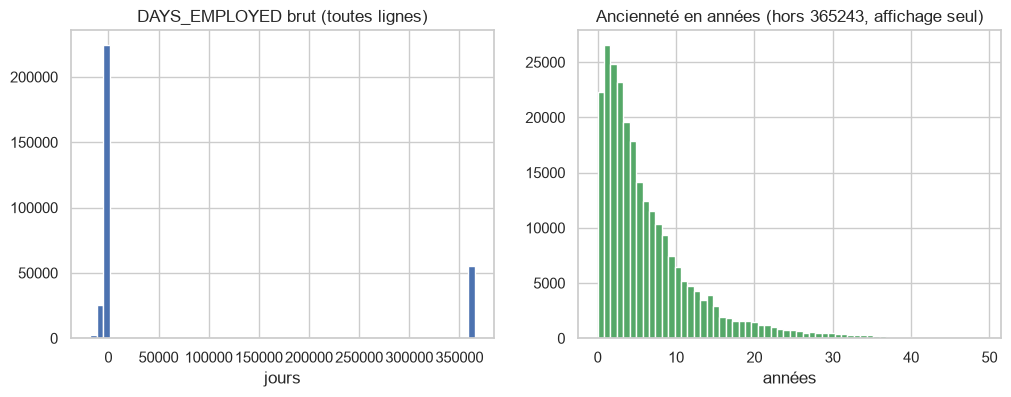

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(df["DAYS_EMPLOYED"], bins=60, color="#4C72B0")
axes[0].set_title("DAYS_EMPLOYED brut (toutes lignes)")
axes[0].set_xlabel("jours")
axes[1].hist(df.loc[~is_anom, "DAYS_EMPLOYED"] / -365.25, bins=60, color="#55A868")
axes[1].set_title("Ancienneté en années (hors 365243, affichage seul)")
axes[1].set_xlabel("années")
save(fig, "03_days_employed_anomaly.png")
plt.show()

## 6. Taux de défaut par modalité

In [21]:
def default_rate(col):
    t = df.groupby(col, dropna=False)["TARGET"].agg(effectif="size", nb_defauts="sum", taux_defaut="mean")
    t["taux_defaut"] = (t["taux_defaut"] * 100).round(2)
    t["pct_population"] = (t["effectif"] / n_rows * 100).round(2)
    return t.sort_values("effectif", ascending=False)

global_rate = df["TARGET"].mean() * 100
rate_tables = {}
for col in ["NAME_INCOME_TYPE", "NAME_CONTRACT_TYPE", "NAME_FAMILY_STATUS"]:
    rate_tables[col] = default_rate(col)
    print(f"=== {col}  (taux global : {global_rate:.2f} %)")
    display(rate_tables[col])

=== NAME_INCOME_TYPE  (taux global : 8.07 %)


,effectif,nb_defauts,taux_defaut,pct_population
NAME_INCOME_TYPE,,,,
Working,158774,15224,9.5900,51.6300
Commercial associate,71617,5360,7.4800,23.2900
Pensioner,55362,2982,5.3900,18.0000
State servant,21703,1249,5.7500,7.0600
Unemployed,22,8,36.3600,0.0100
Student,18,0,0.0000,0.0100
Businessman,10,0,0.0000,0.0000
Maternity leave,5,2,40.0000,0.0000


=== NAME_CONTRACT_TYPE  (taux global : 8.07 %)


,effectif,nb_defauts,taux_defaut,pct_population
NAME_CONTRACT_TYPE,,,,
Cash loans,278232,23221,8.3500,90.4800
Revolving loans,29279,1604,5.4800,9.5200


=== NAME_FAMILY_STATUS  (taux global : 8.07 %)


,effectif,nb_defauts,taux_defaut,pct_population
NAME_FAMILY_STATUS,,,,
Married,196432,14850,7.5600,63.8800
Single / not married,45444,4457,9.8100,14.7800
Civil marriage,29775,2961,9.9400,9.6800
Separated,19770,1620,8.1900,6.4300
Widow,16088,937,5.8200,5.2300
Unknown,2,0,0.0000,0.0000


Figure sauvegardée : reports/figures/04_default_rate_by_category.png


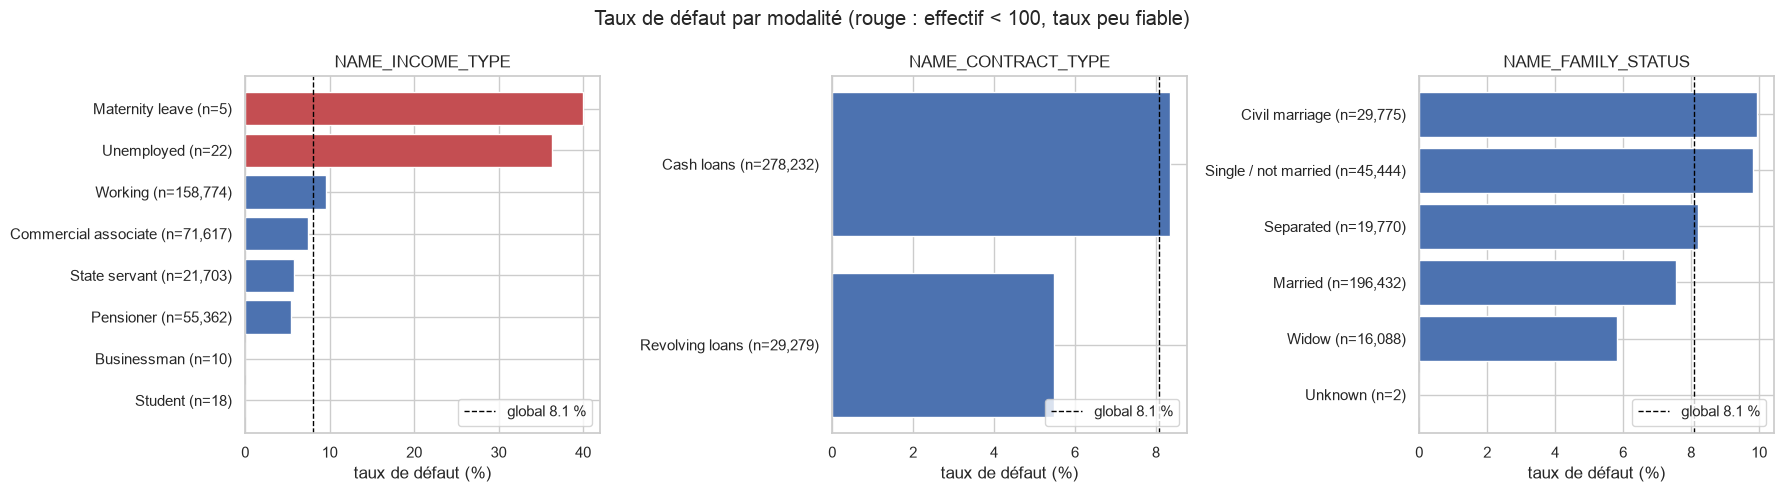

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (col, t) in zip(axes, rate_tables.items()):
    t = t.sort_values("taux_defaut")
    labels = [f"{idx} (n={n:,})" for idx, n in zip(t.index, t["effectif"])]
    colors = ["#C44E52" if n < 100 else "#4C72B0" for n in t["effectif"]]
    ax.barh(labels, t["taux_defaut"], color=colors)
    ax.axvline(global_rate, color="black", ls="--", lw=1, label=f"global {global_rate:.1f} %")
    ax.set_title(col)
    ax.set_xlabel("taux de défaut (%)")
    ax.legend(loc="lower right")
fig.suptitle("Taux de défaut par modalité (rouge : effectif < 100, taux peu fiable)")
fig.tight_layout()
save(fig, "04_default_rate_by_category.png")
plt.show()

## 7. Scores externes `EXT_SOURCE_1/2/3`

La fiche les considère comme une forme d'historique : le modèle banque sera entraîné avec et sans, le modèle client ne les utilisera jamais.

In [23]:
ext_cols = ["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"]
ext = pd.DataFrame({
    "pct_manquants": (df[ext_cols].isna().mean() * 100).round(2),
    "corr_pearson_TARGET": df[ext_cols].corrwith(df["TARGET"]).round(4),
    # Spearman = Pearson sur les rangs (évite la dépendance à scipy)
    "corr_spearman_TARGET": df[ext_cols].rank().corrwith(df["TARGET"].rank()).round(4),
})
display(ext)

n_missing_ext = df[ext_cols].isna().sum(axis=1)
print("Nombre de EXT_SOURCE manquants par ligne :")
print(n_missing_ext.value_counts().sort_index().rename("lignes").to_string())
print()
print("Corrélations entre EXT_SOURCE :")
display(df[ext_cols].corr().round(3))

,pct_manquants,corr_pearson_TARGET,corr_spearman_TARGET
EXT_SOURCE_1,56.3800,-0.1553,-0.1511
EXT_SOURCE_2,0.2100,-0.1605,-0.1473
EXT_SOURCE_3,19.8300,-0.1789,-0.1663


Nombre de EXT_SOURCE manquants par ligne :
0    109589
1    161013
2     36737
3       172

Corrélations entre EXT_SOURCE :


,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3
EXT_SOURCE_1,1.0000,0.2140,0.1870
EXT_SOURCE_2,0.2140,1.0000,0.1090
EXT_SOURCE_3,0.1870,0.1090,1.0000


In [24]:
# Le fait même qu'un score manque est-il lié au défaut ?
miss_rate = pd.DataFrame({
    c: df.groupby(df[c].isna())["TARGET"].mean().mul(100).round(2) for c in ext_cols
}).rename(index={False: "taux_defaut si présent (%)", True: "taux_defaut si manquant (%)"})
miss_rate

,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3
taux_defaut si présent (%),7.5000,8.0700,7.7700
taux_defaut si manquant (%),8.5200,7.8800,9.3100


In [1]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, c in zip(axes, ext_cols):
    sns.kdeplot(data=df, x=c, hue="TARGET", common_norm=False, fill=True, ax=ax)
    ax.set_title(f"{c} · {df[c].isna().mean() * 100:.1f} % manquants · r = {ext.loc[c, 'corr_pearson_TARGET']:.3f}")
fig.suptitle("Distribution des EXT_SOURCE selon TARGET (valeurs présentes uniquement)")
fig.tight_layout()
save(fig, "05_ext_source_by_target.png")
plt.show()

NameError: name 'plt' is not defined

### 7.1 Repère : corrélations des autres variables numériques avec `TARGET`

Pour situer le poids des EXT_SOURCE (affichage seul, pas de sélection de variables).

In [ ]:
corr = df[num_cols].drop(columns=["TARGET", "SK_ID_CURR"]).corrwith(df["TARGET"]).dropna()
top_corr = corr.reindex(corr.abs().sort_values(ascending=False).index).head(15).round(4)
top_corr.rename("corr_pearson_TARGET").to_frame()

,corr_pearson_TARGET
EXT_SOURCE_3,-0.1789
EXT_SOURCE_2,-0.1605
EXT_SOURCE_1,-0.1553
DAYS_BIRTH,0.0782
REGION_RATING_CLIENT_W_CITY,0.0609
REGION_RATING_CLIENT,0.0589
DAYS_LAST_PHONE_CHANGE,0.0552
DAYS_ID_PUBLISH,0.0515
REG_CITY_NOT_WORK_CITY,0.0510
FLAG_EMP_PHONE,0.0460


## 8. Points de contrôle pour les sessions suivantes

Effectifs des groupes utiles pour l'audit d'équité et pour la cible « peu d'historique ».

In [ ]:
age_years = df["DAYS_BIRTH"] / -365.25  # affichage seulement
age_bins = pd.cut(age_years, bins=[18, 25, 30, 40, 50, 60, 70])
print("Taux de défaut par tranche d'âge :")
display(df.groupby(age_bins, observed=True)["TARGET"].agg(effectif="size", taux_defaut="mean")
          .assign(taux_defaut=lambda t: (t["taux_defaut"] * 100).round(2)))
print("Taux de défaut par CODE_GENDER :")
display(default_rate("CODE_GENDER"))

Taux de défaut par tranche d'âge :


,effectif,taux_defaut
DAYS_BIRTH,,
"(18, 25]",12233,12.2900
"(25, 30]",32953,11.1300
"(30, 40]",82349,9.5900
"(40, 50]",76581,7.6400
"(50, 60]",68109,6.1200
"(60, 70]",35286,4.9200


Taux de défaut par CODE_GENDER :


,effectif,nb_defauts,taux_defaut,pct_population
CODE_GENDER,,,,
F,202448,14170,7.0000,65.8300
M,105059,10655,10.1400,34.1600
XNA,4,0,0.0000,0.0000


## Constats

1. **Volume et types** : 307 511 demandes × 122 colonnes (106 numériques, dont 32 flags binaires 0/1 dont 20 `FLAG_DOCUMENT_*`, et 16 catégorielles), environ 325 Mo en mémoire, `SK_ID_CURR` unique.
2. **Cible déséquilibrée** : 24 825 défauts (8,07 %) contre 282 686 remboursements normaux (91,93 %), soit un ratio de **1:11,4**. Ça confirme le choix de l'AUC-ROC/AUC-PR et de la pondération des classes.
3. **Valeurs manquantes** : 67 colonnes sur 122 en ont, 41 dépassent 50 % et 24,4 % des cellules sont vides. Le bloc le plus touché est celui des 47 descripteurs du logement (`_AVG/_MODE/_MEDI`), tous absents ensemble sur 145 755 lignes (47,4 %). Côté catégorielles, `OCCUPATION_TYPE` manque à 31,35 %.
4. **Anomalie `DAYS_EMPLOYED = 365243`** (≈ 1 000 ans) : 55 374 lignes (18,01 %), qui sont exactement les 55 374 `ORGANIZATION_TYPE = "XNA"`. Elles se répartissent en 55 352 `Pensioner` et 22 `Unemployed`. Leur taux de défaut est de **5,40 %**, contre **8,66 %** pour le reste. L'anomalie code donc « pas d'emploi en cours » et elle porte de l'information.
5. **Valeurs suspectes** : `CODE_GENDER = "XNA"` (4 lignes), `NAME_FAMILY_STATUS = "Unknown"` (2) et des modalités minuscules dans `NAME_INCOME_TYPE` (Maternity leave 5, Businessman 10, Student 18, Unemployed 22), dont les taux de défaut (0 % à 40 %) ne sont pas fiables. `AMT_INCOME_TOTAL` monte jusqu'à 117 000 000, soit 795 fois la médiane (147 150).
6. **Taux de défaut par modalité** : `Working` 9,59 % contre `Pensioner` 5,39 % et `State servant` 5,75 %. `Cash loans` 8,35 % contre `Revolving loans` 5,48 %. `Civil marriage` 9,94 % et `Single` 9,81 % contre `Married` 7,56 % et `Widow` 5,82 %. Le défaut baisse aussi avec l'âge : 12,29 % chez les 18-25 ans, 4,92 % chez les 60-70 ans.
7. **EXT_SOURCE** : 56,38 % de manquants pour `EXT_SOURCE_1`, 0,21 % pour `_2` et 19,83 % pour `_3`. Leurs corrélations avec TARGET (−0,155, −0,161, −0,179) sont les trois plus fortes du jeu, plus du double de la suivante (`DAYS_BIRTH`, 0,078). L'absence elle-même est informative : avec `EXT_SOURCE_3` manquant, on a 9,31 % de défauts, contre 7,77 % quand il est présent.
8. **Prix du bien et crédit** : `AMT_GOODS_PRICE` est inférieur à `AMT_CREDIT` dans 64,69 % des lignes, égal dans 35,22 % et supérieur dans seulement 0,08 % (médiane du ratio crédit/prix : 1,12). Les 278 prix manquants sont tous des `Revolving loans`, et pour ces contrats crédit/mensualité vaut exactement 20 en médiane.